# Лабораторная работа №1

Юдин Артём

In [8]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import IPython.display as ipd

ROOT = Path.cwd()
WAV_DIR = ROOT / "data" / "wav"
OUT_DIR = ROOT / "outputs"
sys.path.insert(0, str(ROOT / "scripts"))

import lab_01_audio_inspection as lab_utils

# A — Генераций и проверка аудиофайлов

1. У какого файла, по вашему ожиданию, будет самая высокая RMS-энергия?

**У файла с шумами, так как они добавляют энергию к аудио**

2. В каком файле, по вашему ожиданию, искажение волновой формы будет наиболее заметным?

**У клипнутого, поскольку будет обрезание верхушек у сигнала**

3. В каком файле, по вашему ожиданию, спектральные переходы будут наиболее размытыми?

**У файла с реверберациями из-за симуляции затуханий и отражений будет общее смазывание**

# B — Статистика аудио

In [10]:
rows = []
for path in WAV_DIR.glob("*.wav"):
    audio, sr = lab_utils.load_audio(path)
    rows.append(lab_utils.summarize_audio(path.name, audio, sr))

lab_utils.write_summary_csv(rows, OUT_DIR / "audio_summary.csv")
summary = pd.DataFrame(rows).set_index("filename")
summary

,sample_rate_hz,duration_s,num_samples,peak_amplitude,rms,silence_fraction,clipping_fraction
filename,,,,,,,
noisy_speech_like.wav,16000,5.200,83200,0.920013,0.265441,0.077200,0.000012
reverberant_speech_like.wav,16000,5.200,83200,0.880005,0.216411,0.385096,0.000108
speed_perturbed_speech_like.wav,16000,4.522,72348,0.780029,0.250186,0.389244,0.000014
clipped_speech_like.wav,16000,5.200,83200,0.340027,0.245213,0.298690,0.463798
clean_speech_like.wav,16000,5.200,83200,0.780029,0.250151,0.388930,0.000024


1. У какого файла доля клиппинга ненулевая или необычно высокая? Почему?

**Ненулевая она у всех аудио. Вторая по величине - `reverberant_speech_like.wav`. Это может быть из-за сложения амплитуд изначально и отражённого сигналов и последующее их срезание**

2. У какого файла самая короткая длительность? Почему?

**У `speed_perturbed_speech_like`. Потому что мы ускорили его и не западили**

3. Почему доля тишины может быть важна для ASR на длинных записях?

**Потому что модели могут галлюцинировать (было с Whisper) + большой контекст хранить для аттеншена -> можем не влезть по памяти**

# C — Волновая форма

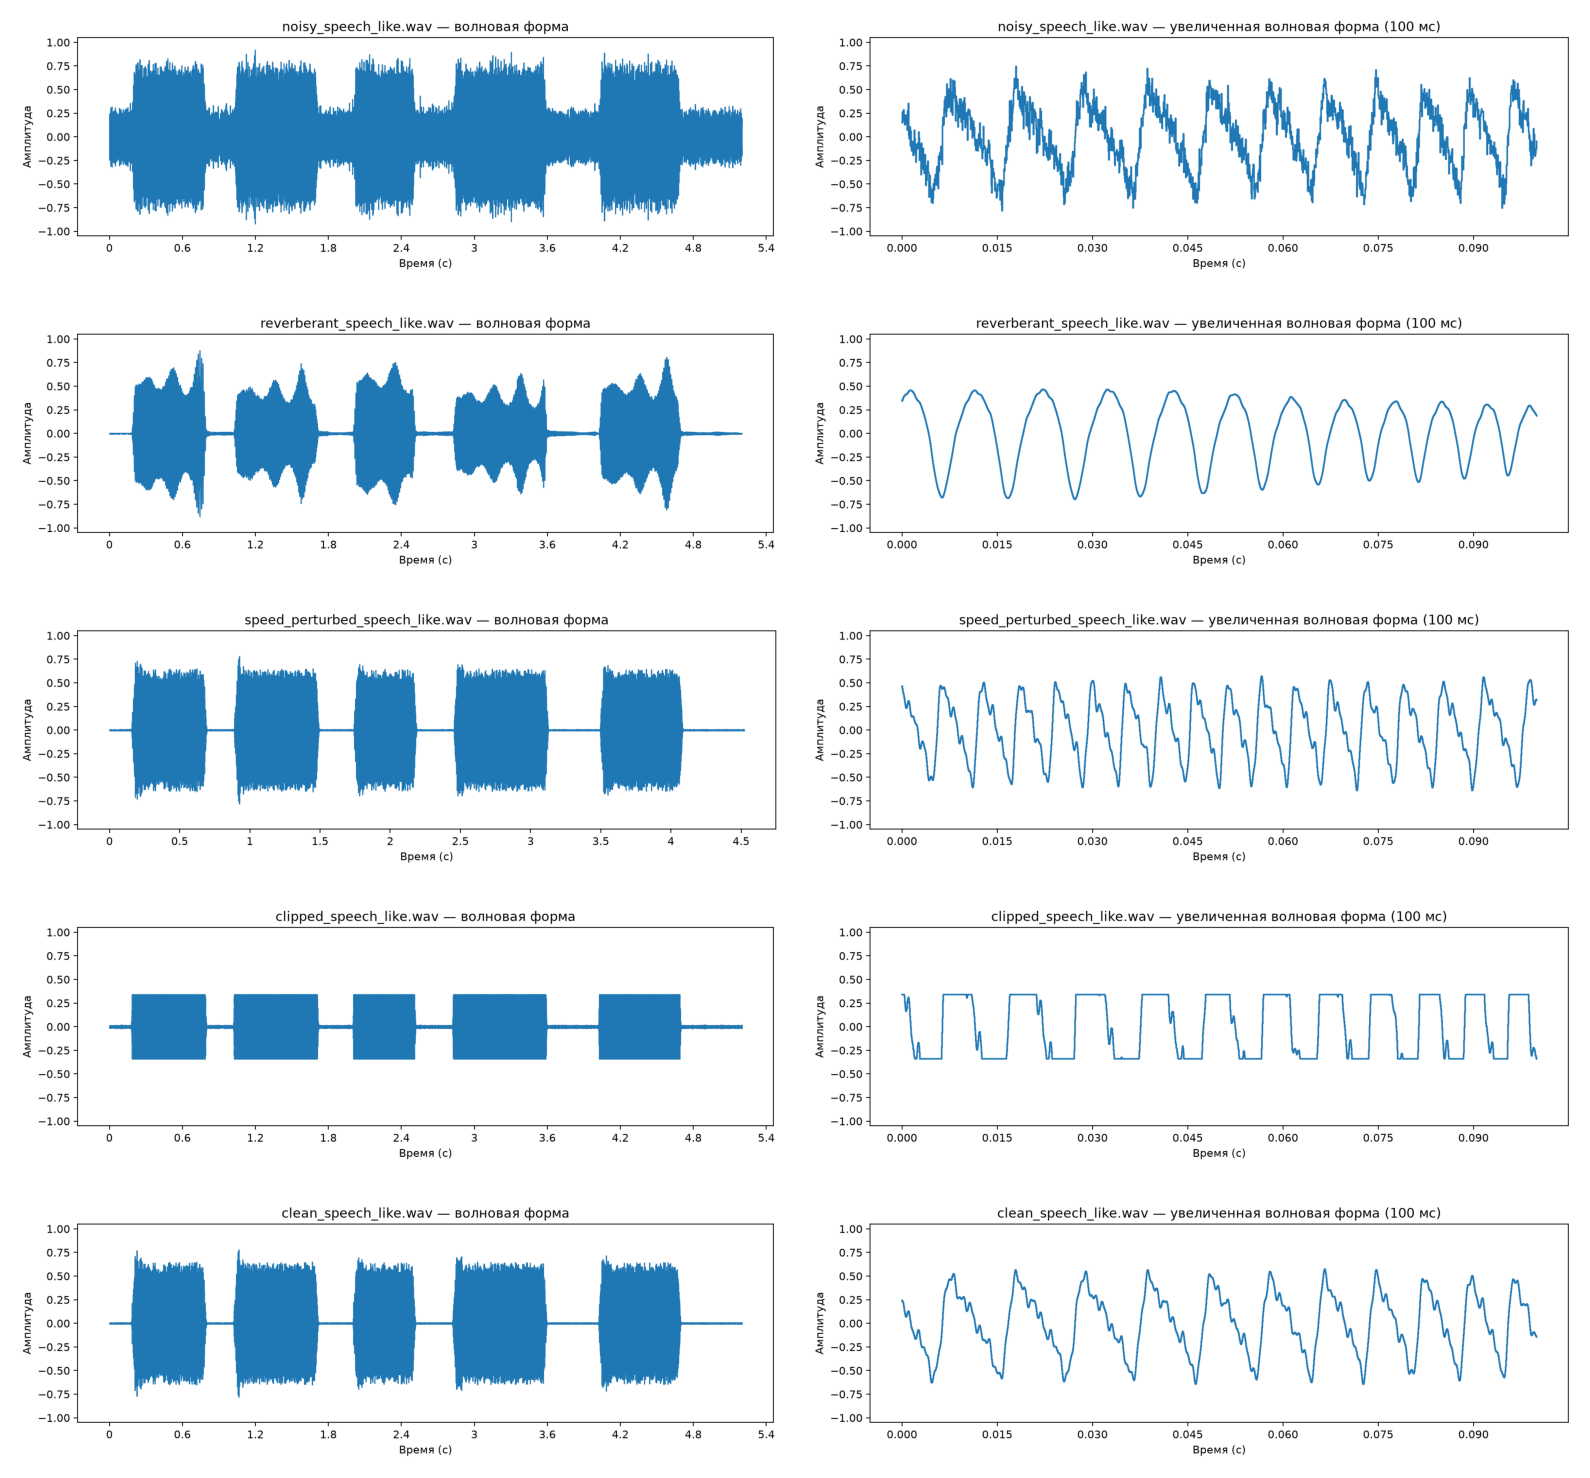

In [16]:
left_suffix = "waveform"
right_suffix = "waveform_zoom"
all_files = [row["filename"] for row in rows]

fig, axes = plt.subplots(len(all_files), 2, figsize=(16, 3 * len(all_files)))
axes = np.atleast_2d(axes)

for row_axes, name in zip(axes, all_files):
    stem = Path(name).stem
    for ax, suffix in zip(row_axes, (left_suffix, right_suffix)):
        img_path = OUT_DIR / f"{stem}_{suffix}.png"
        ax.imshow(mpimg.imread(img_path))
        ax.axis("off")

plt.tight_layout()
plt.show()

1. Какое искажение легче всего увидеть на волновой форме?

**Клиппинг, потому что он выглядит как квадраты, и у шума, потому что сегменты тишины ненулевые**

2. Как выглядит клиппинг?

**Квадраты на полной или на обрезанные кочки при зуме**

3. Почему одной амплитуды может быть недостаточно, чтобы понять содержание речи?

**Амплитуда показывает громкость сигнала, но нет никакой информации о частотной составляющей, которая кодирует смысловую нагрузку**

# D — Лог-спектрограмма STFT

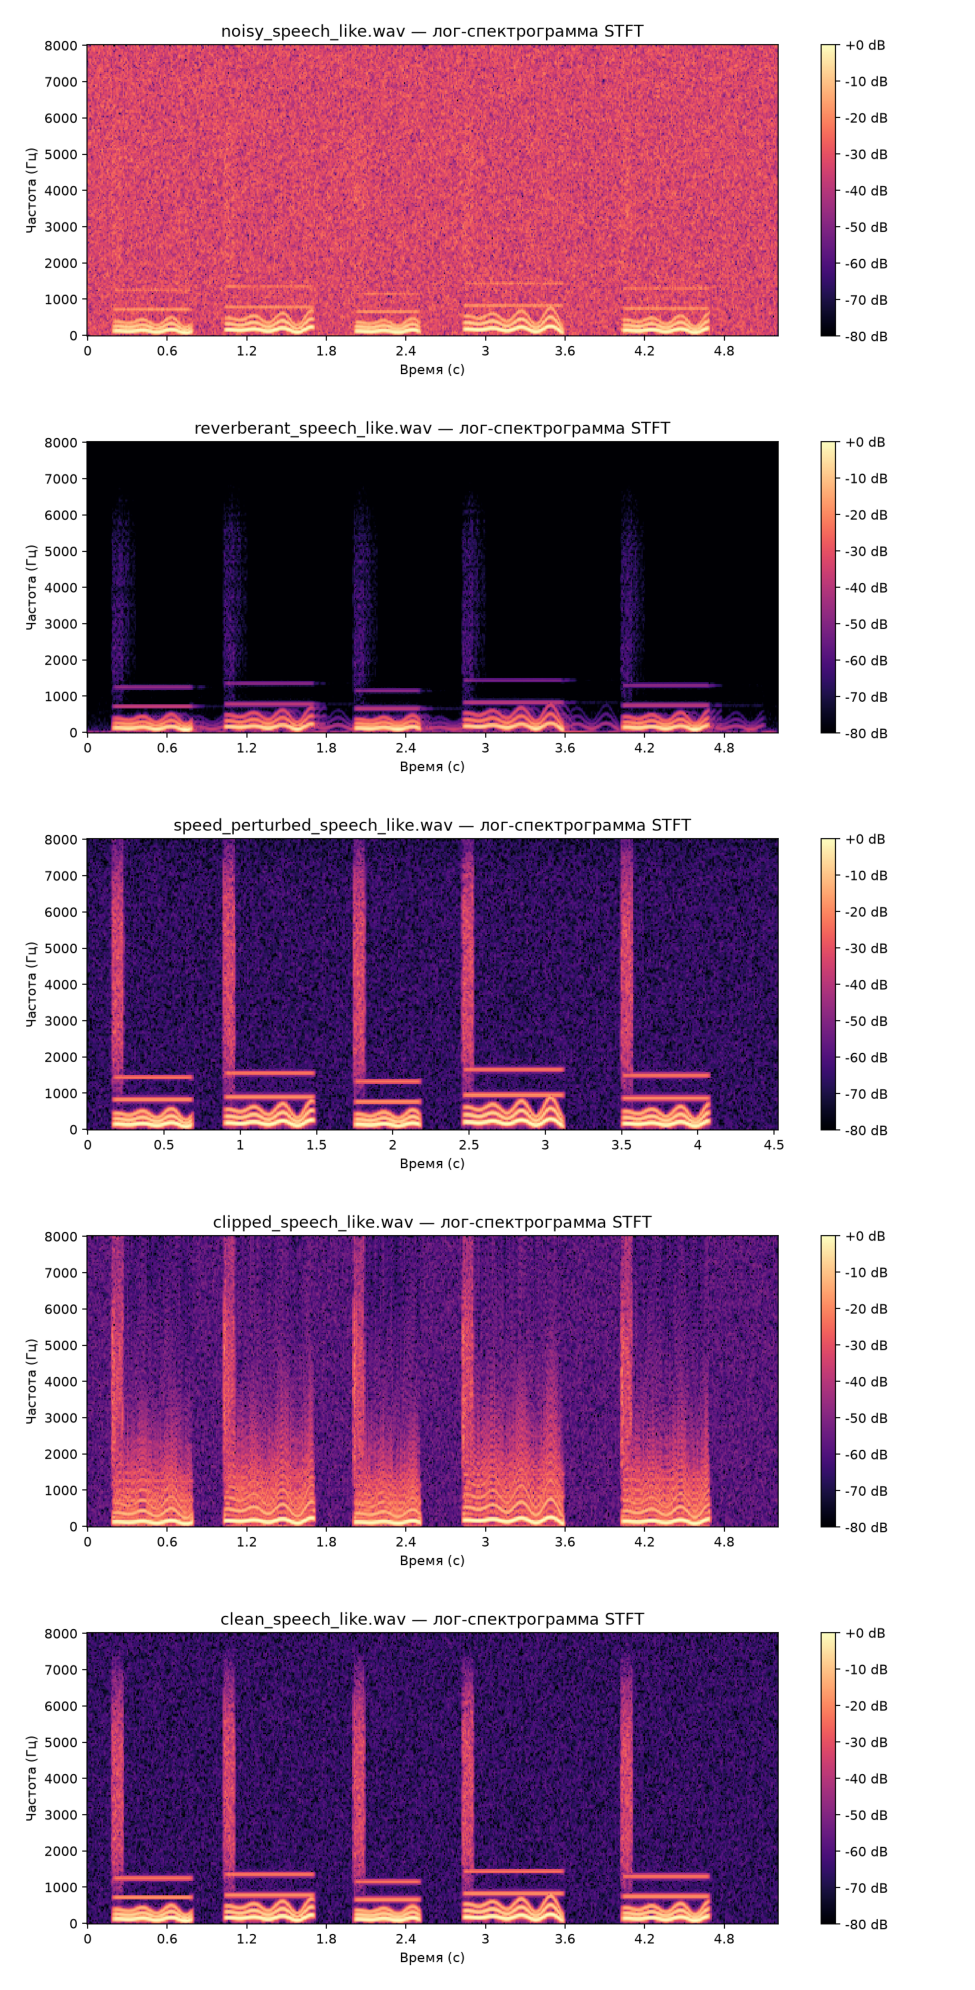

In [ ]:
def plot_specs(suffix: str):
    fig, axes = plt.subplots(len(all_files), 1, figsize=(10, 4 * len(all_files)))
    axes = np.atleast_1d(axes)

    for ax, name in zip(axes, all_files):
        stem = Path(name).stem
        img_path = OUT_DIR / f"{stem}_{suffix}.png"
        ax.imshow(mpimg.imread(img_path))
        ax.axis("off")

    plt.tight_layout()
    plt.show()


plot_specs("stft_spectrogram")


1. В каком файле больше всего широкополосной высокочастотной энергии?

**Аддитивный шум имеет равномерную спектральную плотность, поэтому заполняет и высокую частоту**

2. Как реверберация меняет time-frequency паттерн?

**Отражения создают размытие границ между разными звуками**

3. Почему шум может вызывать замены или удаления в ASR?

**Информация, которую несётся сигнал, стирается таким образом (например, тихо произнесённая речь). Может пропасть возможность в целом слышать слова**

# E — Log-Mel-спектрограмма

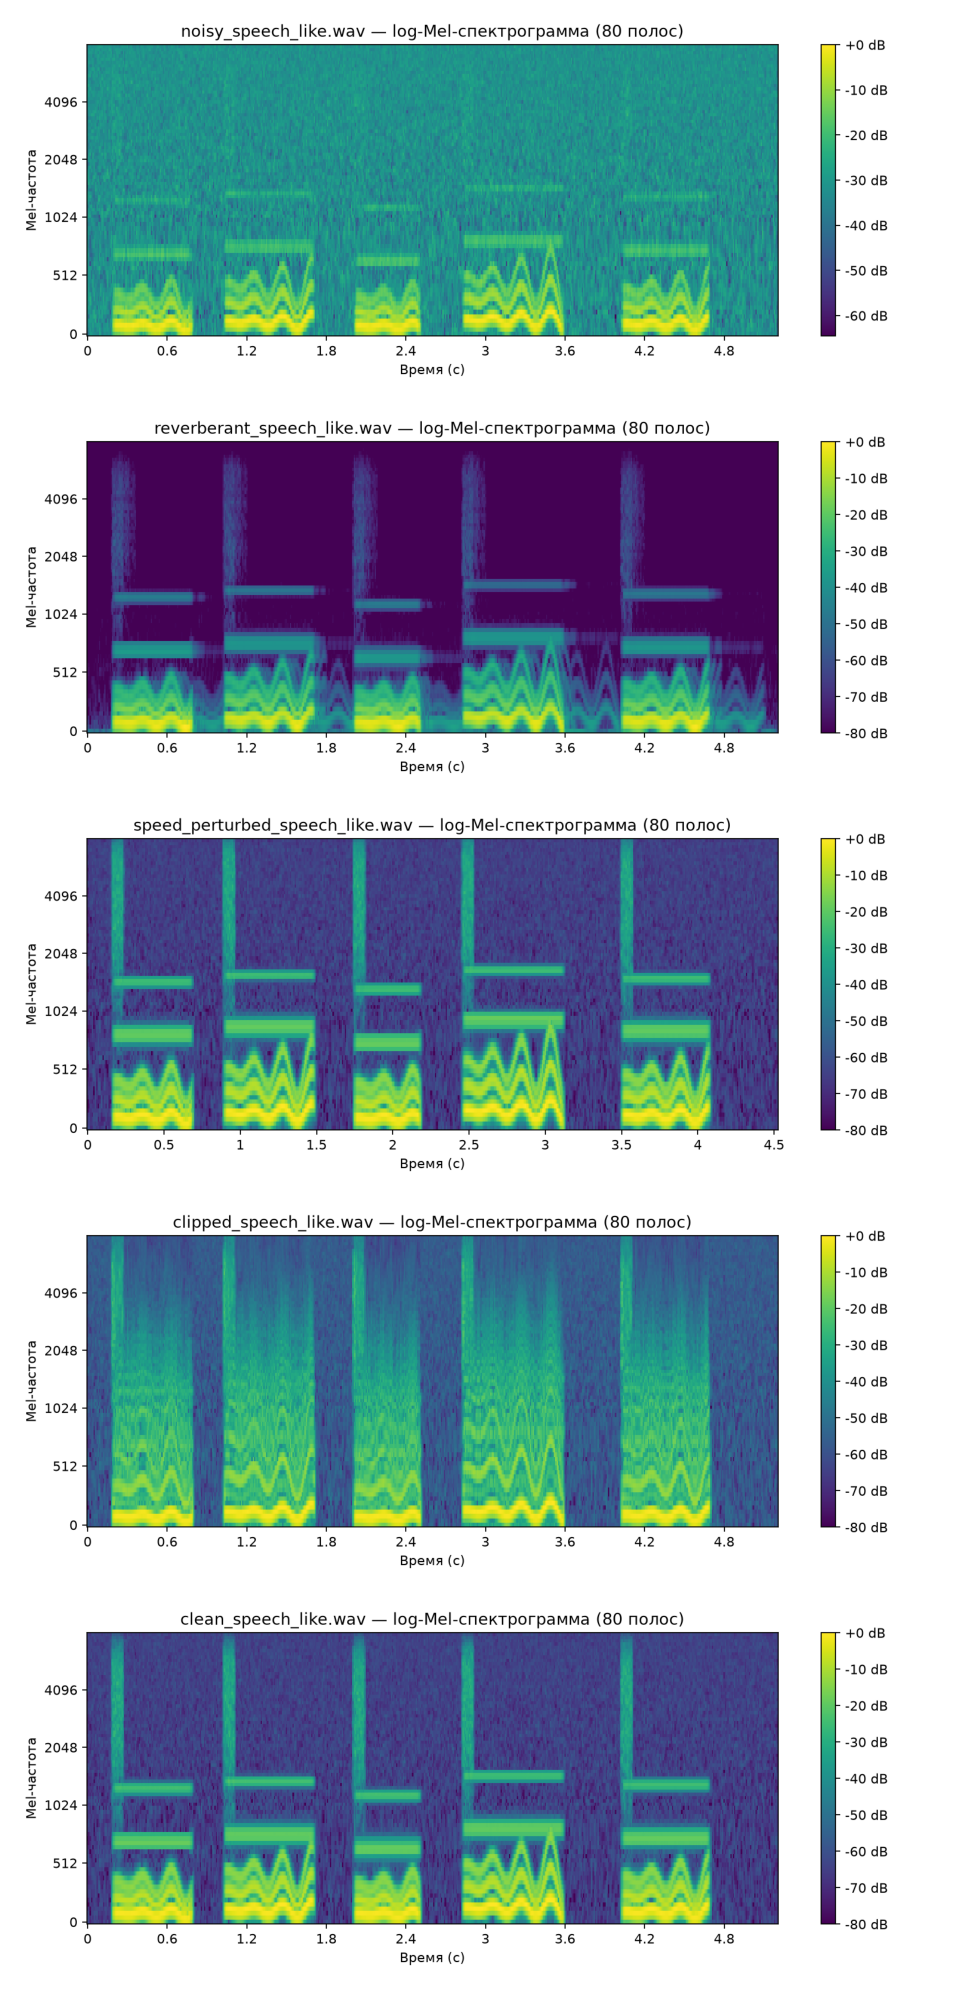

In [23]:
plot_specs("log_mel")

1. Какую информацию легче увидеть на log-Mel, чем на волновой форме?

**Волновое представление показывает изменение громкости сигнала от времени, в то время как log-Mel показывает гармоническую составляющую. В особенности - низкочастотную**

2. Какая информация теряется или сжимается по сравнению с линейно-частотной STFT?

**Большее спектральное разрешение на низких частотах у log-Mel протим теряющейся из-за банок информации на высоких частотах у STFT**

3. Почему логарифмические энергии полезны для речи?

**Это ближе к тому, как люди слышат звуки. Плюс разница энергии у гласных и согласных сжимается за счёт логарифмирования**

# F — MFCC

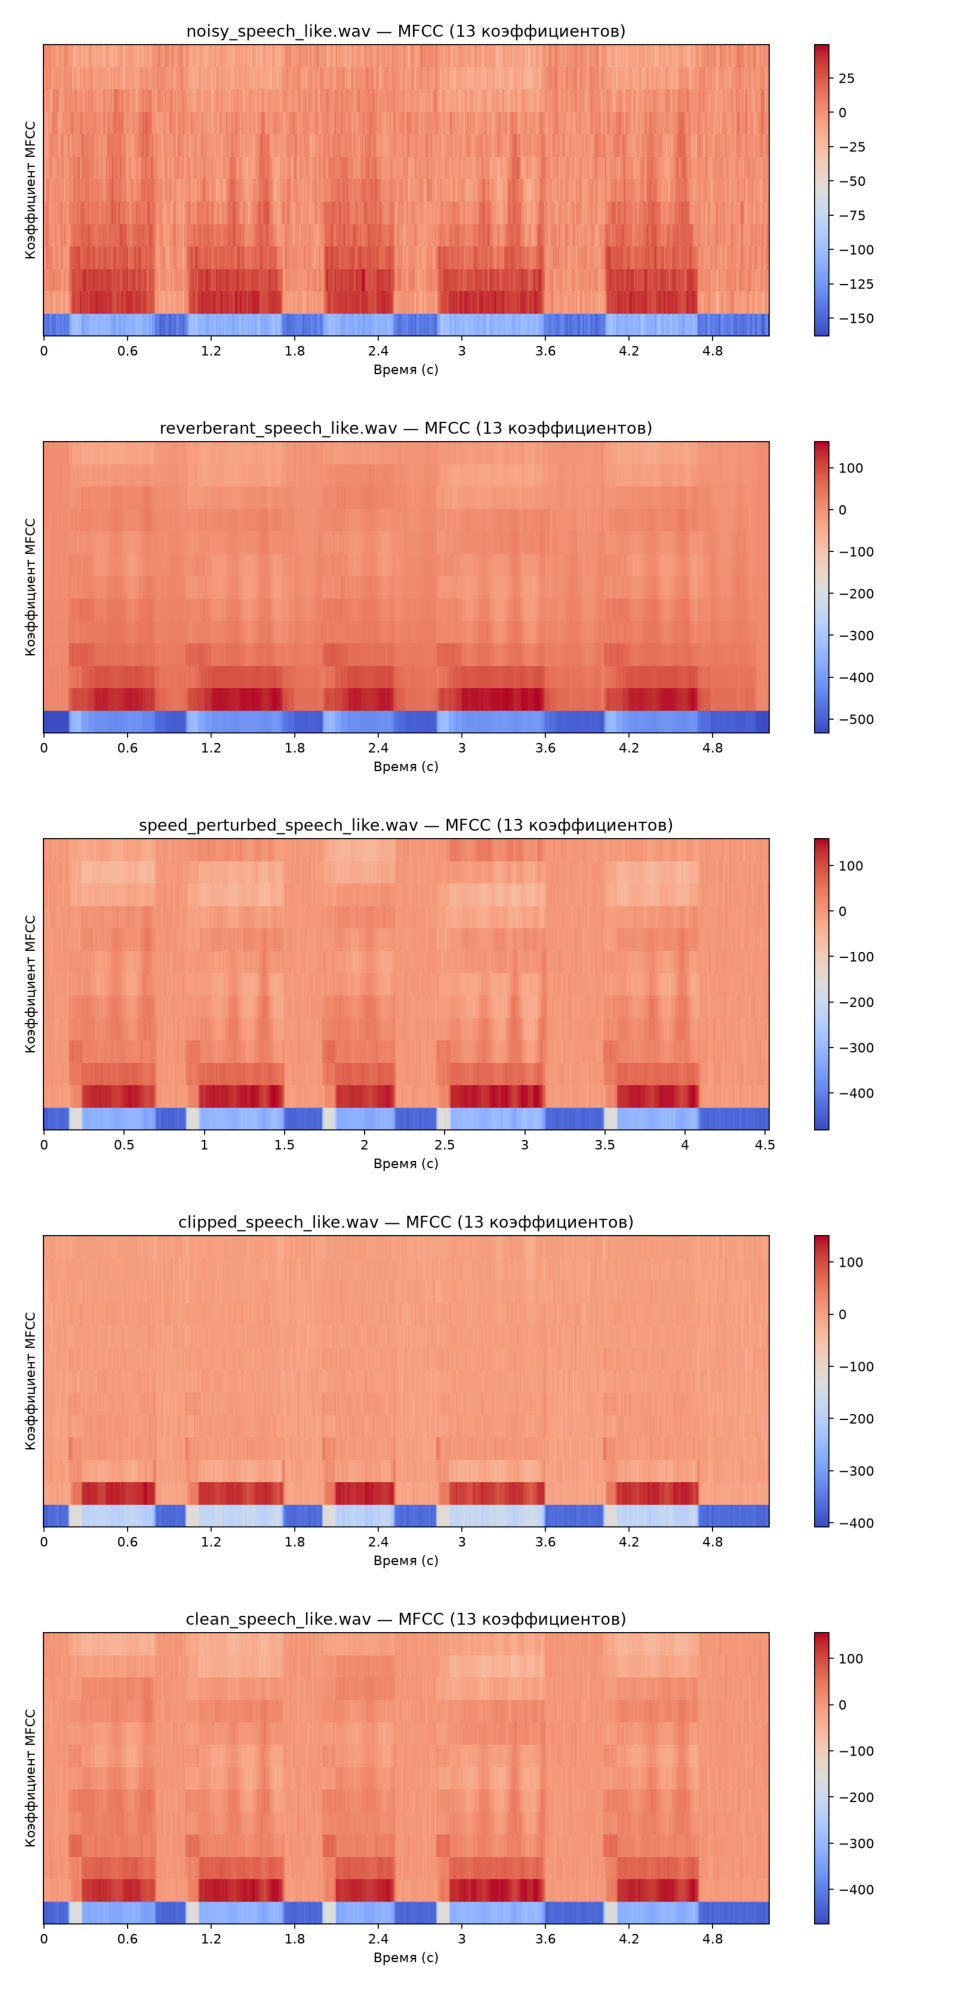

In [24]:
plot_specs("mfcc")

1. Чем визуально графики MFCC отличаются от log-Mel?

**Разрешение по оси y стало меньше у MFCC**

2. Почему компактное представление может быть полезным?

**Решение проблемы размерности. Плюс - DCT декоррелирует информацию между соседними банками, что важно для классических линейных МЛ моделей**

3. Почему современный нейросетевой ASR может предпочитать более богатые log-Mel признаки?

**Современные подходы справляются с большими объёмами данных и сжатие не нужно. Сохранение спектрального информации может помочь повысить точность**

# G — Сравнение чистого и искажённого аудио

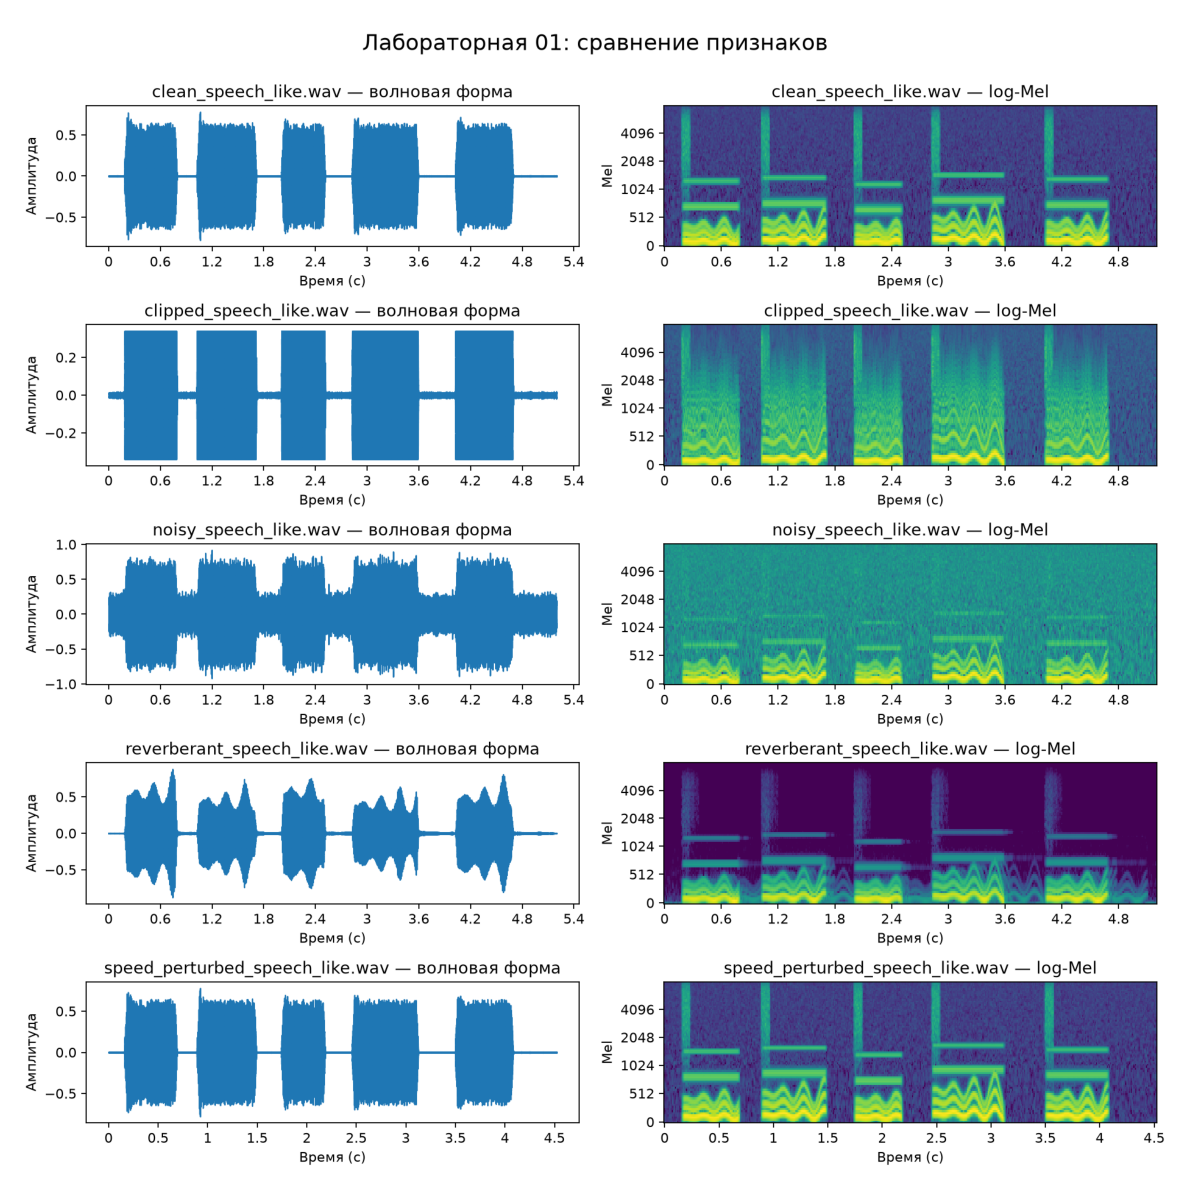

In [ ]:
fig = plt.figure(figsize=(12, 13))

plt.imshow(mpimg.imread(OUT_DIR / "feature_comparison_contact_sheet.png"))
plt.axis("off")
plt.tight_layout()
plt.show()

| Искажения    | Что изменилось в волновой форме?                                                  | Что изменилось в спектрограмме/log-Mel?                                                                        | Возможный тип ошибки ASR                                                          |
|--------------|-----------------------------------------------------------------------------------|----------------------------------------------------------------------------------------------------------------|-----------------------------------------------------------------------------------|
| Шум          | Появились хаотичные колебания, зоны тишины перестали иметь околонулевую амплитуду | Весь спектр заполнило зерновым шумом, из-за чего хуже видно небольшие спектральные детали                      | Удаление тихих слов, замена из-за неразборчивости, галлюцинации после тишины/шума |
| Реверберация | Форма у волн в моменты речи стло более неоднородной                               | Столбы в высоких частотах стали менее чёткими, общий ненулевой шум пропал, появились хвосты на низких частотах | Вставка из-за хвостов, плохое определение границ речи                             |
| Клиппинг     | Сигнал теперь выглядит как квадраты (как уже говорил пару раз выше)               | Частотная информация из низких чатсот растянулась и на верхние частоты                                         | Замена, ухудшение пунктуации/регистра из-за изменение тоннальности речи           |
| Ускорение    | Ось x стала короче                                                                | Также только уменьшение числе вдоль x                                                                          | Неверная временная метка                                                          |

# Дополнительное задание

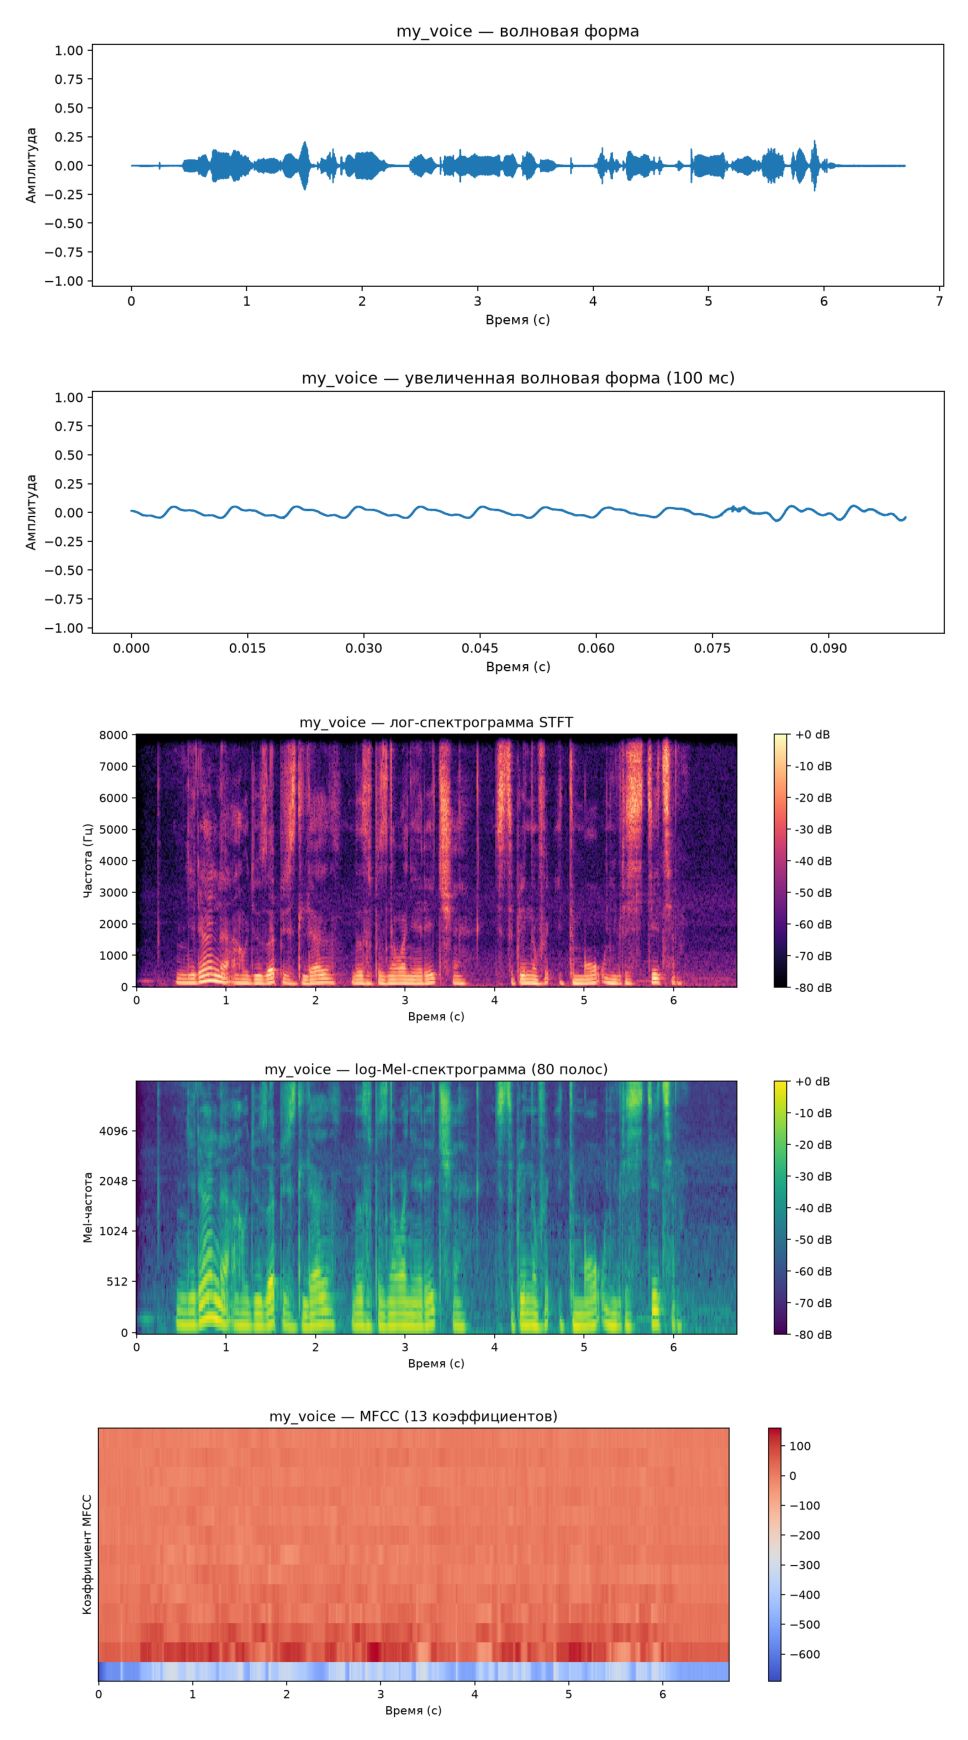

In [30]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

my_wav, sr = librosa.load(WAV_DIR / "voice.wav", sr=16_000)
name = "my_voice"

lab_utils.save_waveform(my_wav, sr, name, OUT_DIR / f"{name}_waveform.png")
lab_utils.save_waveform(
    my_wav, sr, name, OUT_DIR / f"{name}_waveform_zoom.png", zoom=True
)
lab_utils.save_stft_spectrogram(
    my_wav, sr, name, OUT_DIR / f"{name}_stft_spectrogram.png"
)
lab_utils.save_log_mel(my_wav, sr, name, OUT_DIR / f"{name}_log_mel.png")
lab_utils.save_mfcc(my_wav, sr, name, OUT_DIR / f"{name}_mfcc.png")

suffixes = ["waveform", "waveform_zoom", "stft_spectrogram", "log_mel", "mfcc"]

fig, axes = plt.subplots(len(suffixes), 1, figsize=(10, 3.5 * len(suffixes)))
axes = np.atleast_1d(axes)

stem = Path(name).stem
for ax, suffix in zip(axes, suffixes):
    img_path = OUT_DIR / f"{stem}_{suffix}.png"
    ax.imshow(mpimg.imread(img_path))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
rows = []
for path in WAV_DIR.glob("*.wav"):
    audio, sr = lab_utils.load_audio(path)
    rows.append(lab_utils.summarize_audio(path.name, audio, sr))

lab_utils.write_summary_csv(rows, OUT_DIR / "audio_summary.csv")
summary = pd.DataFrame(rows).set_index("filename")
summary

,sample_rate_hz,duration_s,num_samples,peak_amplitude,rms,silence_fraction,clipping_fraction
filename,,,,,,,
voice.wav,16000,6.700,107200,0.218129,0.028359,0.391632,0.000009
noisy_speech_like.wav,16000,5.200,83200,0.920013,0.265441,0.077200,0.000012
reverberant_speech_like.wav,16000,5.200,83200,0.880005,0.216411,0.385096,0.000108
speed_perturbed_speech_like.wav,16000,4.522,72348,0.780029,0.250186,0.389244,0.000014
clipped_speech_like.wav,16000,5.200,83200,0.340027,0.245213,0.298690,0.463798
clean_speech_like.wav,16000,5.200,83200,0.780029,0.250151,0.388930,0.000024


Наш голос имеет более неравномерную временную структуру, большие перепады по громкости.
По спектру видны фоновые следы от акустики комнаты, форманты имеют более сильный изгиб
У MFCC паузы между словами не отображаются как разрывы с резким переходом